In [ ]:
#This program aims for sentiment analysis
#Please run the scrap_msg to get the information needed first
#https://www.epochconverter.com/
#numpy 1.22.1, transformers 4.35, cuda 11.8

from telethon import TelegramClient
import asyncio
from datetime import timezone,datetime,timedelta
import os
import pandas as pd
import pickle
import time
from cleantext import clean
import re
import calendar
from os import listdir
from os.path import isfile, join
from ast import literal_eval

import spacy
import nltk
from nltk.stem.porter import *      #rip spacy did not have Porter Stemmer
from nltk.stem import WordNetLemmatizer
from transformers import AutoModelForSequenceClassification
from transformers import TFAutoModelForSequenceClassification
from transformers import AutoTokenizer
from scipy.special import softmax
import csv
import urllib.request

from sklearn.model_selection import train_test_split
from scipy.stats import mannwhitneyu
from scipy.stats import kruskal

import torch
from transformers import BertTokenizer, BertForSequenceClassification, Trainer, TrainingArguments
from transformers import Trainer, TrainingArguments, TrainerCallback
from transformers.trainer_callback import TrainerControl, TrainerState
from transformers.training_args import TrainingArguments
from datasets import Dataset
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_score

import wordcloud
import bbcode
from nltk.corpus import stopwords
import gensim
from PIL import Image

if not (os.path.isdir("data")):
    raise FileNotFoundError("Please run the scrap_msg to get information needed.")

wwbotuserid=198626752

In [21]:
userall=pd.read_csv("data\\userall.csv",converters={"nickname":literal_eval})
print(userall.to_markdown())

|     |      userid |   lierate |   lieratewithnoact |   gameplayed |   winrate | common_role        |   survivalrate |    fbrate |   fbcount | nickname                         |
|----:|------------:|----------:|-------------------:|-------------:|----------:|:-------------------|---------------:|----------:|----------:|:---------------------------------|
|   0 |  1007570205 | 0.142857  |          0.0714286 |           14 |  0.714286 | a cultist          |       0.714286 | 0         |         0 | ['loki']                         |
|   1 |  1018375312 | 0         |          0         |            2 |  1        | a mason            |       0.5      | 0         |         0 | ['senku']                        |
|   2 |  1080215864 | 0         |          0         |            2 |  1        | the fool           |       1        | 0         |         0 | ['septyan']                      |
|   3 |  1084817391 | 0.05      |          0.05      |           20 |  0.65     | a mason            |   

First step: Inspect game length with the number of message first, see the average msg (length/number) per minute

In [2]:
col_name=["id","gametime","player_count","msg_count","words_count"]
gamedata=pd.read_csv("data\\gamedata.csv",converters={"players":literal_eval})
count_df=pd.DataFrame({},columns=col_name)

for games in gamedata["id"]:
    with open (f"data\\games\\{games}.ob", "rb") as fp:
        readlist=pickle.load(fp)
        newlist=[x for x in readlist if x["sender_id"].user_id in gamedata[gamedata.id==games]["players"].values[0]]    #only count things that are players
    words_count=0
    
    for items in newlist:
        words_count+=len(items["content"].split())
    msg_count=len(newlist)

    temp=pd.DataFrame([[games,gamedata[gamedata.id==games]["game_length"].values[0],gamedata[gamedata.id==games]["player_count"].values[0],msg_count,words_count]],columns=col_name)
    count_df=pd.concat([count_df,temp],ignore_index=True)

print(count_df.to_markdown())

|     |         id |   gametime |   player_count |   msg_count |   words_count |
|----:|-----------:|-----------:|---------------:|------------:|--------------:|
|   0 | 1741356097 |        226 |              7 |          39 |           116 |
|   1 | 1741354005 |        302 |              7 |          21 |            48 |
|   2 | 1741352171 |        472 |              6 |          83 |           242 |
|   3 | 1741351468 |        264 |              5 |          19 |            67 |
|   4 | 1741264064 |        272 |              7 |          10 |            23 |
|   5 | 1741260992 |        452 |              8 |          19 |            36 |
|   6 | 1741188804 |        574 |              8 |          48 |            93 |
|   7 | 1741181402 |        575 |              9 |          77 |           165 |
|   8 | 1741180366 |        476 |              9 |          81 |           184 |
|   9 | 1741179625 |        443 |              7 |          75 |           153 |
|  10 | 1741178473 |        

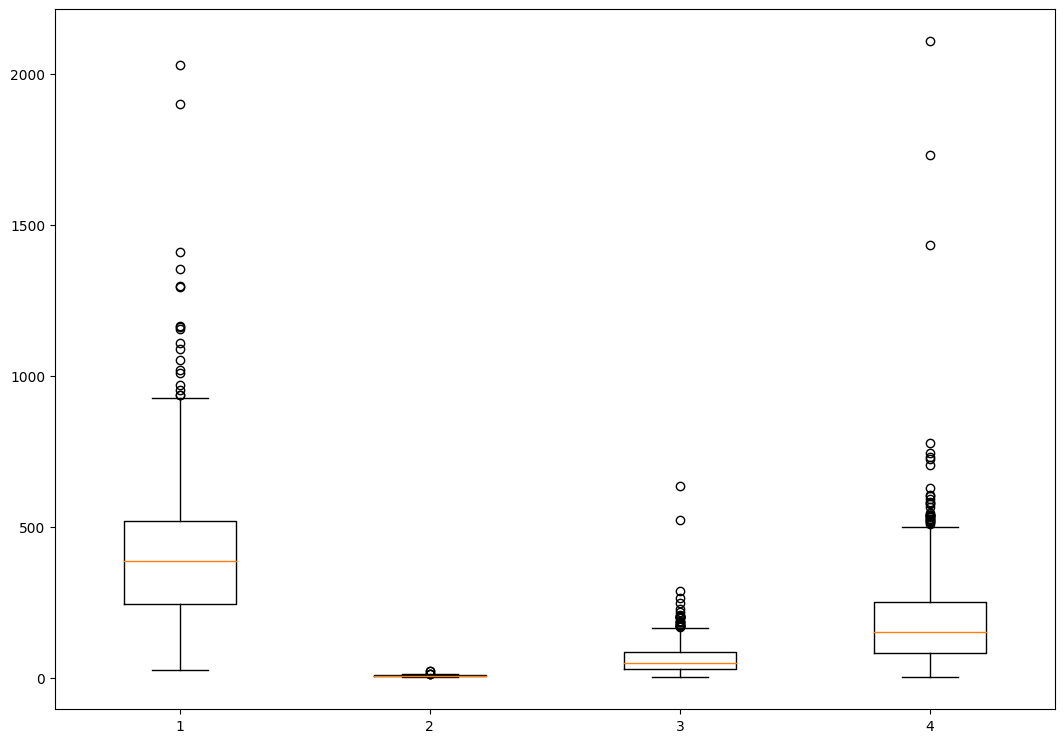

Timeoutliers:18
Playeroutliers:5
Msgoutliers:27
Wordoutliers:89
|     |         id |   gametime |   player_count |   msg_count |   words_count |
|----:|-----------:|-----------:|---------------:|------------:|--------------:|
|  30 | 1740907049 |        900 |             10 |         137 |           482 |
|  47 | 1740659609 |        657 |             10 |         156 |           528 |
|  51 | 1740656545 |        579 |              6 |          91 |           353 |
|  58 | 1740580587 |        600 |              7 |         114 |           342 |
|  60 | 1740578976 |        971 |             11 |         185 |           471 |
|  61 | 1740577626 |        643 |              8 |         175 |           523 |
|  63 | 1740575246 |        901 |              9 |         220 |           724 |
|  79 | 1740405728 |        788 |             11 |         141 |           436 |
|  86 | 1740322660 |        429 |             10 |          96 |           362 |
|  87 | 1740321853 |        592 |            

In [3]:
plot=[count_df["gametime"].values,count_df["player_count"].values,count_df["msg_count"].values,count_df["words_count"].values]
fig=plt.figure(figsize =(10, 7))
ax=fig.add_axes([0, 0, 1, 1])
bp=ax.boxplot(plot)
plt.show()

timeiqr=np.percentile(count_df["gametime"], 75, method='midpoint')-np.percentile(count_df["gametime"], 25, method='midpoint')
playeriqr=np.percentile(count_df["player_count"], 75, method='midpoint')-np.percentile(count_df["player_count"], 25, method='midpoint')
msgiqr=np.percentile(count_df["msg_count"], 75, method='midpoint')-np.percentile(count_df["msg_count"], 25, method='midpoint')
wordiqr=np.percentile(count_df["words_count"], 75, method='midpoint')-np.percentile(count_df["words_count"], 25, method='midpoint')

timeoutlier=count_df[(count_df.gametime<(np.percentile(count_df["gametime"], 25, method='midpoint')-1.5*timeiqr)) | (count_df.gametime>(np.percentile(count_df["gametime"], 75, method='midpoint')+1.5*timeiqr))]
playeroutlier=count_df[(count_df.player_count<(np.percentile(count_df["player_count"], 25, method='midpoint')-1.5*playeriqr)) | (count_df.player_count>(np.percentile(count_df["player_count"], 75, method='midpoint')+1.5*playeriqr))]
msgoutlier=count_df[(count_df.msg_count<(np.percentile(count_df["msg_count"], 25, method='midpoint')-1.5*msgiqr)) | (count_df.msg_count>(np.percentile(count_df["msg_count"], 75, method='midpoint')+1.5*msgiqr))]
wordoutlier=count_df[(count_df.words_count<(np.percentile(count_df["words_count"], 25, method='midpoint')-1.5*wordiqr)) | (count_df.words_count>(np.percentile(count_df["words_count"], 75, method='midpoint')+1.5*msgiqr))]

print("Timeoutliers:"+str(len(timeoutlier))+"\nPlayeroutliers:"+str(len(playeroutlier))+"\nMsgoutliers:"+str(len(msgoutlier))+"\nWordoutliers:"+str(len(wordoutlier)))
print(wordoutlier.to_markdown())

In [4]:
x=count_df[["gametime","player_count"]]
y=count_df["msg_count"]

reg=LinearRegression().fit(x, y)
print(reg.score(x, y))

coefs=reg.coef_
intercept=reg.intercept_
feature_names=x.columns

# Format the equation
terms=[f"{coef:.4f} * {name}" for coef, name in zip(coefs, feature_names)]
equation=f"y = {intercept:.4f} + {' + '.join(terms)}"

# Print the equation
print("Linear Regression Equation:", equation)

0.7359548943216314
Linear Regression Equation: y = -67.6078 + 0.1330 * gametime + 9.9118 * player_count


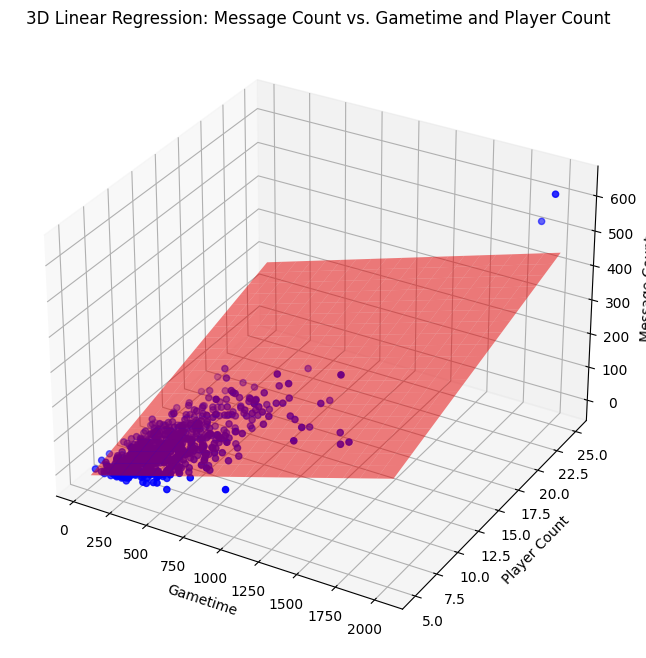

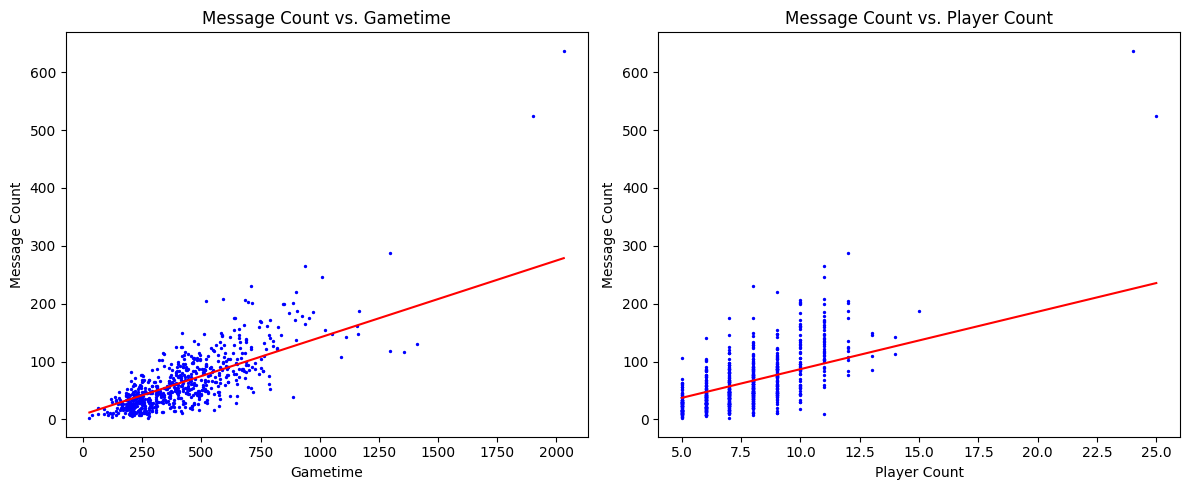

Mean CV R²: 0.6704196371021984


In [5]:
fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Scatter plot of data points
ax.scatter(x['gametime'], x['player_count'], y, color='blue', label='Data Points')

# Create a meshgrid for the regression plane
x1_range = np.linspace(x['gametime'].min(), x['gametime'].max(), 20)
x2_range = np.linspace(x['player_count'].min(), x['player_count'].max(), 20)
x1_grid, x2_grid = np.meshgrid(x1_range, x2_range)

# Compute the predicted msg_count for the grid
y_grid = intercept + coefs[0] * x1_grid + coefs[1] * x2_grid

# Plot the regression plane
ax.plot_surface(x1_grid, x2_grid, y_grid, color='red', alpha=0.5, label='Regression Plane')

# Labels and title
ax.set_xlabel('Gametime')
ax.set_ylabel('Player Count')
ax.set_zlabel('Message Count')
ax.set_title('3D Linear Regression: Message Count vs. Gametime and Player Count')

# Legend (note: plot_surface legend is tricky, may not show)
#plt.legend()
plt.show()

# --- 2D Scatter Plots with Regression Lines ---
# Plot 1: msg_count vs. gametime (holding player_count at mean)
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(x['gametime'], y, color='blue', label='Data Points',s=2)

# Compute regression line for gametime (fix player_count at mean)
mean_player_count = x['player_count'].mean()
gametime_range = np.linspace(x['gametime'].min(), x['gametime'].max(), 100)
y_pred = intercept + coefs[0] * gametime_range + coefs[1] * mean_player_count
plt.plot(gametime_range, y_pred, color='red', label='Regression Line')

plt.xlabel('Gametime')
plt.ylabel('Message Count')
plt.title('Message Count vs. Gametime')
#plt.legend()

# Plot 2: msg_count vs. player_count (holding gametime at mean)
plt.subplot(1, 2, 2)
plt.scatter(x['player_count'], y, color='blue', label='Data Points',s=2)

# Compute regression line for player_count (fix gametime at mean)
mean_gametime = x['gametime'].mean()
player_count_range = np.linspace(x['player_count'].min(), x['player_count'].max(), 100)
y_pred = intercept + coefs[0] * mean_gametime + coefs[1] * player_count_range
plt.plot(player_count_range, y_pred, color='red', label='Regression Line')

plt.xlabel('Player Count')
plt.ylabel('Message Count')
plt.title('Message Count vs. Player Count')
#plt.legend()

plt.tight_layout()
plt.show()

scores=cross_val_score(reg, x, y, cv=5, scoring='r2')
print("Mean CV R²:", scores.mean())

#Step 1 done

Step 2: Try sentiment analysis for each player, give overall review for each of the player

In [ ]:
task="sentiment"
#task='emotion'      #original is "sentiment"
MODEL=f"cardiffnlp/twitter-roberta-base-{task}"
tokenizer=AutoTokenizer.from_pretrained(MODEL)

device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model=AutoModelForSequenceClassification.from_pretrained(MODEL)
model.to(device)
model.eval()  # Set to evaluation mode

if not (os.path.isdir(MODEL)):
    # PT
    tokenizer.save_pretrained(MODEL)
    model.save_pretrained(MODEL)

# download label mapping
labels=[]
mapping_link=f"https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/{task}/mapping.txt"
with urllib.request.urlopen(mapping_link) as f:
    html=f.read().decode('utf-8').split("\n")
    csvreader = csv.reader(html, delimiter='\t')
labels=[row[1] for row in csvreader if len(row) > 1]

In [4]:
#All the function and stuffs you need for making wordcloud :)
#Think about if you want to remove stop words? (no act?)

Extend_stop_words=stopwords.words('english')
Extend_stop_words.remove("no")  #maybe delete "no" stands for no act?

parser=bbcode.Parser()
cList = {
  "ain't": "am not",
  "aren't": "are not",
  "can't": "cannot",
  "can't've": "cannot have",
  "'cause": "because",
  "could've": "could have",
  "couldn't": "could not",
  "couldn't've": "could not have",
  "didn't": "did not",
  "doesn't": "does not",
  "don't": "do not",
  "hadn't": "had not",
  "hadn't've": "had not have",
  "hasn't": "has not",
  "haven't": "have not",
  "he'd": "he would",
  "he'd've": "he would have",
  "he'll": "he will",
  "he'll've": "he will have",
  "he's": "he is",
  "how'd": "how did",
  "how'd'y": "how do you",
  "how'll": "how will",
  "how's": "how is",
  "I'd": "I would",
  "I'd've": "I would have",
  "I'll": "I will",
  "I'll've": "I will have",
  "I'm": "I am",
  "I've": "I have",
  "isn't": "is not",
  "it'd": "it had",
  "it'd've": "it would have",
  "it'll": "it will",
  "it'll've": "it will have",
  "it's": "it is",
  "let's": "let us",
  "ma'am": "madam",
  "mayn't": "may not",
  "might've": "might have",
  "mightn't": "might not",
  "mightn't've": "might not have",
  "must've": "must have",
  "mustn't": "must not",
  "mustn't've": "must not have",
  "needn't": "need not",
  "needn't've": "need not have",
  "o'clock": "of the clock",
  "oughtn't": "ought not",
  "oughtn't've": "ought not have",
  "shan't": "shall not",
  "sha'n't": "shall not",
  "shan't've": "shall not have",
  "she'd": "she would",
  "she'd've": "she would have",
  "she'll": "she will",
  "she'll've": "she will have",
  "she's": "she is",
  "should've": "should have",
  "shouldn't": "should not",
  "shouldn't've": "should not have",
  "so've": "so have",
  "so's": "so is",
  "that'd": "that would",
  "that'd've": "that would have",
  "that's": "that is",
  "there'd": "there had",
  "there'd've": "there would have",
  "there's": "there is",
  "they'd": "they would",
  "they'd've": "they would have",
  "they'll": "they will",
  "they'll've": "they will have",
  "they're": "they are",
  "they've": "they have",
  "to've": "to have",
  "wasn't": "was not",
  "we'd": "we had",
  "we'd've": "we would have",
  "we'll": "we will",
  "we'll've": "we will have",
  "we're": "we are",
  "we've": "we have",
  "weren't": "were not",
  "what'll": "what will",
  "what'll've": "what will have",
  "what're": "what are",
  "what's": "what is",
  "what've": "what have",
  "when's": "when is",
  "when've": "when have",
  "where'd": "where did",
  "where's": "where is",
  "where've": "where have",
  "who'll": "who will",
  "who'll've": "who will have",
  "who's": "who is",
  "who've": "who have",
  "why's": "why is",
  "why've": "why have",
  "will've": "will have",
  "won't": "will not",
  "won't've": "will not have",
  "would've": "would have",
  "wouldn't": "would not",
  "wouldn't've": "would not have",
  "y'all": "you all",
  "y'alls": "you alls",
  "y'all'd": "you all would",
  "y'all'd've": "you all would have",
  "y'all're": "you all are",
  "y'all've": "you all have",
  "you'd": "you had",
  "you'd've": "you would have",
  "you'll": "you you will",
  "you'll've": "you you will have",
  "you're": "you are",
  "you've": "you have"
}

c_re = re.compile('(%s)' % '|'.join(cList.keys()))

def expandContractions(text, c_re=c_re):
    def replace(match):
        return cList[match.group(0)]
    return c_re.sub(replace, text.lower())
#https://gist.github.com/nealrs/96342d8231b75cf4bb82

num_dict = {'0': 'zero','1': 'one','2': 'two','3': 'three','4': 'four','5': 'five','6': 'six','7': 'seven','8': 'eight','9': 'nine' }   #use that to convert numbers to eng words

def numword(im_words):
    if(len(im_words) == 1 and im_words in '0123456789'):
        reword=num_dict[im_words]
    elif(len(str(im_words)) == 1 and im_words in '0123456789'):
        reword=num_dict(str(im_words))
    else:
        reword=im_words
    return reword

#Using Extend_stop_words declared in above
Extend_stop_words=[a for a in Extend_stop_words if a not in ['zero','one','two','three','four','five','six','seven','eight','nine']]

def rm_stopwords(doc):
    rewords=[numword(p) for p in doc if p!='' and p not in Extend_stop_words]
    return rewords

def par_clean(intext):
    fstep=parser.strip(intext)
    intext=expandContractions(fstep)
    intext=re.split(r'\W+',intext)
    intext=[numword(a) for a in intext]
    intext=[words for words in intext if words not in Extend_stop_words and len(words)>1 and len(words) <= 20]
    return intext

In [ ]:
if not (os.path.isdir("data\\wordcloud")):
    os.mkdir("data\\wordcloud")

plt.rcParams['figure.figsize']=2000,1000

onlyfiles=[f for f in listdir("data\\player") if isfile(join("data\\player", f))]
columns=["gameid","userid","content","label","score"]
try:
    allconvdf=pd.read_csv("data\\allconvdf.csv")
except:
    allconvdf=pd.DataFrame(columns=columns)

for items in onlyfiles:
    allconversation=[]
    userid=int(items[:-4])
    record=pd.read_csv(f"data\\player\\{items}")

    allgameid=record["gameid"].values
    for games in allgameid:
        with open (f"data\\games\\{games}.ob", "rb") as fp:
            readlist=pickle.load(fp)
            readlist=[x for x in readlist if x["sender_id"].user_id==userid]
            for things in readlist:
                allconversation.append([things["content"],games])

    allconversation=[x for x in allconversation if x[0]!=""]   #removing all things that are empty in chat (probably gif?)
    if userid in list(allconvdf["userid"]):
        allconversationnew=[x for x in allconversation if (x[1] not in list(allconvdf["gameid"]))]    #removing existing ones in the saved df
    else:
        allconversationnew=allconversation

    for things in allconversationnew:   #use the new one as need to output to allconvdf
        encoded_input=tokenizer(things[0], return_tensors='pt').to(device)
        try:
            output=model(**encoded_input)
        except: #RIP I doomed myself with my hahaha message
            l="N/A"
            s=0
        else:
            scores=output[0][0].detach().cpu().numpy()
            scores=softmax(scores)
            l=labels[np.argmax(scores)]
            s=scores[np.argmax(scores)]

        temp=pd.DataFrame([[things[1],userid,things[0],l,s]],columns=columns)   #save it to dataframe
        allconvdf=pd.concat([allconvdf,temp],ignore_index=True)

    #do the wordcloud (each user) here
    list_all_words=[]
    for things in allconversation:  #use the old allconversation as you need all words to make wordcloud
        list_all_words.extend(par_clean(str(things[0])))
    wfreq=nltk.FreqDist(list_all_words)
    text=' '.join(a for a in list_all_words)
    try:
        wordcd=wordcloud.WordCloud(width=2000, height=1000, max_words=50).generate(text)
    except:
        img=np.zeros((1000,2000,1),dtype="uint8")
        img=img.squeeze()
        pil_img=Image.fromarray(img, mode='L')  
        pil_img.save(f"data\\wordcloud\\{userid}.png")
        continue    #don't need to run the following code

    plt.figure(figsize=(20,10))
    plt.imshow(wordcd, interpolation='bilinear')
    plt.axis("off")
    plt.margins(0, 0)
    plt.gca().set_frame_on(False)
    plt.savefig(f"data\\wordcloud\\{userid}.png",bbox_inches='tight',pad_inches=0,transparent=True,dpi=300)
    plt.close()
    

print(allconvdf.head(100).to_markdown())
allconvdf.to_csv("data\\allconvdf.csv",index=False) #save the output file


#do the wordcloud for sum up
all_words=[]
for things in allconvdf["content"]:
    all_words.extend(par_clean(str(things)))
wfreq=nltk.FreqDist(all_words)
print(wfreq.most_common(50))
text=' '.join(a for a in all_words)
wordcd=wordcloud.WordCloud(width=2000, height=1000, max_words=50).generate(text)
plt.figure(figsize=(20,10))
plt.imshow(wordcd, interpolation='bilinear')
plt.axis("off")
plt.margins(0, 0)
plt.gca().set_frame_on(False)
plt.savefig("data\\allusers.png",bbox_inches='tight',pad_inches=0,transparent=True,dpi=300)
plt.show()

|    |     gameid |     userid | content                          | label    |    score |
|---:|-----------:|-----------:|:---------------------------------|:---------|---------:|
|  0 | 1740586366 | 1007570205 | vg                               | sadness  | 0.313994 |
|  1 | 1740586366 | 1007570205 | hamtaro wru                      | anger    | 0.342668 |
|  2 | 1740586366 | 1007570205 | okay                             | joy      | 0.350814 |
|  3 | 1740586366 | 1007570205 | give name                        | joy      | 0.408528 |
|  4 | 1740586366 | 1007570205 | also i'm                         | sadness  | 0.535748 |
|  5 | 1740586366 | 1007570205 | 9:39pm                           | joy      | 0.547182 |
|  6 | 1740586366 | 1007570205 | ooh                              | joy      | 0.711841 |
|  7 | 1740586366 | 1007570205 | ooh yeah                         | joy      | 0.870975 |
|  8 | 1737096641 | 1007570205 | im vg                            | sadness  | 0.789566 |
|  9 | 173

'\n#do the wordcloud for sum up\nall_words=[]\nfor things in allconvdf["content"]:\n    all_words.extend(par_clean(str(things)))\nwfreq=nltk.FreqDist(all_words)\nprint(wfreq.most_common(50))\ntext=\' \'.join(a for a in all_words)\nwordcd=wordcloud.WordCloud(width=2000, height=1000, max_words=50).generate(text)\nplt.figure(figsize=(20,10))\nplt.imshow(wordcd, interpolation=\'bilinear\')\nplt.axis("off")\nplt.margins(0, 0)\nplt.gca().set_frame_on(False)\nplt.savefig("data\\allusers.png",bbox_inches=\'tight\',pad_inches=0,transparent=True,dpi=300)\nplt.show()\n'

In [11]:
print(allconvdf.shape)
print(wfreq.most_common(100))

(40824, 5)
[('no', 3029), ('oh', 1574), ('act', 1414), ('im', 1388), ('ok', 717), ('afk', 717), ('one', 696), ('lynch', 649), ('hahaha', 644), ('cc', 606), ('kirs', 603), ('go', 576), ('emo', 576), ('miku', 571), ('ww', 550), ('arso', 484), ('ota', 473), ('faa', 465), ('game', 433), ('dont', 418), ('role', 408), ('kill', 401), ('nice', 400), ('seer', 381), ('wow', 381), ('lol', 376), ('carol', 365), ('lmao', 352), ('omg', 349), ('sad', 320), ('like', 316), ('see', 316), ('got', 313), ('still', 311), ('think', 303), ('wait', 292), ('two', 292), ('sk', 291), ('day', 290), ('night', 288), ('tanner', 279), ('yes', 278), ('idk', 275), ('egg', 269), ('time', 268), ('die', 261), ('safe', 260), ('okay', 259), ('try', 256), ('know', 253), ('let', 253), ('name', 252), ('first', 252), ('maybe', 250), ('eat', 242), ('mason', 235), ('yea', 234), ('ur', 232), ('natsu', 231), ('harlot', 227), ('ch', 224), ('fool', 222), ('us', 222), ('didnt', 220), ('today', 218), ('said', 217), ('vote', 216), ('cult

In [2]:
#This cell can run independently
#Inspect the whole group sentiment
allconvdf=pd.read_csv("data\\allconvdf.csv")
distinctgameid=allconvdf["gameid"].unique()
gamesentiment=[]

for games in distinctgameid:
    thatgame=allconvdf[allconvdf.gameid==games]
    sentiment=thatgame.label.value_counts().items()
    gamesentiment.append(list(sentiment))

for things in zip(distinctgameid,gamesentiment):
    print(things)

(1740586366, [('neutral', 48), ('negative', 4), ('positive', 3)])
(1737096641, [('neutral', 29), ('negative', 5), ('positive', 1)])
(1737096197, [('neutral', 53), ('negative', 8), ('positive', 1)])
(1737025532, [('neutral', 37), ('negative', 3), ('positive', 1)])
(1737024713, [('neutral', 41), ('negative', 8), ('positive', 5)])
(1736779275, [('neutral', 21), ('negative', 5)])
(1736778482, [('neutral', 10)])
(1736777671, [('neutral', 146), ('negative', 26), ('positive', 6)])
(1736773950, [('neutral', 36), ('negative', 9), ('positive', 1)])
(1736772785, [('neutral', 65), ('negative', 13), ('positive', 3)])
(1736767831, [('neutral', 103), ('negative', 17), ('positive', 5)])
(1736766091, [('neutral', 72), ('negative', 17), ('positive', 3)])
(1736765045, [('neutral', 35), ('negative', 4), ('positive', 2)])
(1740146568, [('neutral', 63), ('negative', 15), ('positive', 7)])
(1740145735, [('neutral', 37), ('negative', 11), ('positive', 4)])
(1738847073, [('neutral', 62), ('negative', 13), ('po

In [24]:
#This cell can run independently
#Inspect sentiment for each player
columns=["userid","negative","neutral","positive","unknown","totalgames"]
sentimentdf=pd.DataFrame(columns=columns)

onlyfiles=[f for f in listdir("data\\player") if isfile(join("data\\player", f))]
allconvdf=pd.read_csv("data\\allconvdf.csv")

for items in onlyfiles:
    usersentiment=[]
    userid=items[:-4]
    userdb=pd.read_csv(f"data\\player\\{items}")
    usergameid=userdb["gameid"]
    temp=pd.DataFrame([[userid,0,0,0,0,0]],columns=columns)

    for moreitems in usergameid:
        games=allconvdf[((allconvdf.userid==int(userid)) & (allconvdf.gameid==moreitems))]
        sentiment=games.label.value_counts().items()
        usersentiment.append(list(sentiment))

    for things in zip(usergameid,usersentiment):
        try:
            temp.at[0,things[1][0][0]]+=1
        except:
            temp.at[0,"unknown"]+=1
    
    temp.at[0,"totalgames"]=int(temp["negative"]+temp["neutral"]+temp["positive"]+temp["unknown"])
    sentimentdf=pd.concat([sentimentdf,temp],ignore_index=True)

print(sentimentdf.to_markdown())

|     |      userid |   negative |   neutral |   positive |   unknown |   totalgames |
|----:|------------:|-----------:|----------:|-----------:|----------:|-------------:|
|   0 |  1007570205 |          0 |        13 |          0 |         1 |           14 |
|   1 |  1018375312 |          0 |         0 |          0 |         2 |            2 |
|   2 |  1080215864 |          1 |         1 |          0 |         0 |            2 |
|   3 |  1084817391 |          4 |        13 |          1 |         2 |           20 |
|   4 |   116330040 |          1 |         0 |          0 |         0 |            1 |
|   5 |  1182603889 |          1 |        53 |          0 |         2 |           56 |
|   6 |  1285660197 |          0 |         0 |          0 |         1 |            1 |
|   7 |  1334471689 |          0 |         0 |          0 |         1 |            1 |
|   8 |  1339911576 |         37 |       240 |          7 |        64 |          348 |
|   9 |   140409452 |          0 |         

In [4]:
gaming=allconvdf[allconvdf.gameid==1737642155]
print(gaming.to_markdown())

#This part is done?
#Seems that sentiment is not a suitable tool to predict user's roles

|       |     gameid |     userid | content                                                     | label    |    score |
|------:|-----------:|-----------:|:------------------------------------------------------------|:---------|---------:|
|  6391 | 1737642155 |  167932826 | cc hunter                                                   | neutral  | 0.716614 |
|  6392 | 1737642155 |  167932826 | faa died                                                    | negative | 0.628757 |
|  6393 | 1737642155 |  167932826 | ikr                                                         | neutral  | 0.51979  |
|  6394 | 1737642155 |  167932826 | this ran stml                                               | neutral  | 0.66083  |
|  6395 | 1737642155 |  167932826 | u said...........                                           | neutral  | 0.710709 |
|  6396 | 1737642155 |  167932826 | sad                                                         | negative | 0.728344 |
|  6397 | 1737642155 |  167932826 | u sa

Step 3: Try train model directly (ignore sentiment scores) to predict user role

In [2]:
#This function help transform roles into one of these categories: VG/WW/cult/ota/crazy
def determinedangerous(roles):
    if roles in ["a werewolf","the sorcerer","the wolf cub","the lycan","the alpha wolf","the snow wolf"]:
        return "ww"
    elif roles=="a cultist":
        return "cult"
    elif roles in ["the doppelganger", "the wild child", "cupid", "the thief"]:
        return "ota"
    elif roles in ["the serial killer","the arsonist"]:
        return "crazy"
    else:
        return "vg"

senlist=[]
rolelist=[]
allconvdf=pd.read_csv("data\\allconvdf.csv")
uniquegameid=allconvdf["gameid"].unique()
for gameids in uniquegameid:
    selectedgames=allconvdf[allconvdf.gameid==gameids]
    uniqueplayerid=selectedgames["userid"].unique()
    for userids in uniqueplayerid:
        userdatabase=pd.read_csv(f"data\\player\\{str(userids)}.csv")
        listofcontent=list(selectedgames[selectedgames.userid==userids]["content"])
        userroles=str(userdatabase[userdatabase.gameid==gameids]["role"].values[0])

        senlist.append(listofcontent)
        rolelist.append(determinedangerous(userroles))

'''data={
    "text":senlist,     #only 4672,rip
    "label":rolelist
}'''
split_senlist=[]
split_rolelist=[]

for conv,lab in zip(senlist,rolelist):
    for i in range(1,len(conv)+1):
        split_senlist.append(conv[:i])
        split_rolelist.append(lab)

data={
    "text":split_senlist,
    "label":split_rolelist
}

label_map={"vg": 0, "ww": 1, "cult": 2, "ota": 3, "crazy": 4}
data["label"]=[label_map[label] for label in data["label"]]

print(len(data["label"]))

40824


In [ ]:
dataset=Dataset.from_dict(data)

# Concatenate sentences
dataset=dataset.map(lambda x: {"combined_text": " [SEP] ".join(x["text"])})

# Load tokenizer and model
tokenizer=BertTokenizer.from_pretrained("bert-base-uncased")
model=BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=5)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
model.eval()  # Set to evaluation mode

# Tokenize data
def tokenize_function(examples):
    return tokenizer(examples["combined_text"], padding="max_length", truncation=True, max_length=128)

tokenized_dataset=dataset.map(tokenize_function, batched=True)
tokenized_dataset=tokenized_dataset.remove_columns(["text", "combined_text"])
tokenized_dataset=tokenized_dataset.rename_column("label", "labels")

def compute_metrics(pred):
    labels=pred.label_ids
    preds=np.argmax(pred.predictions, axis=1)
    accuracy=accuracy_score(labels, preds)
    precision, recall, f1, _=precision_recall_fscore_support(labels, preds, average="binary")
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

class PauseAtCheckpointCallback(TrainerCallback):
    def __init__(self, pause_duration=180):
        self.pause_duration = pause_duration
    
    def on_save(self, args: TrainingArguments, state: TrainerState, control: TrainerControl, **kwargs):
        """
        Called after a checkpoint is saved. Pauses for the specified duration.
        """
        print(f"Checkpoint saved at step {state.global_step}. Pausing for {self.pause_duration} seconds...")
        time.sleep(self.pause_duration)
        print("Resuming training...")
        return control

# Training arguments
training_args=TrainingArguments(
    output_dir="./predictroles",
    learning_rate=2e-5,
    per_device_train_batch_size=8,
    num_train_epochs=3,
    weight_decay=0.01,
    logging_steps=50,
    save_steps=400,
    evaluation_strategy="no",
)

# Trainer
trainer=Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset,
    compute_metrics=compute_metrics,
    callbacks=[PauseAtCheckpointCallback(pause_duration=180)],
)

# Train
#trainer.train()
trainer.train(resume_from_checkpoint=True)

output_dir="./predictroles_final"  # Directory to save the model
# Save the model
trainer.save_model(output_dir)
# Save the tokenizer
tokenizer.save_pretrained(output_dir)
print(f"Model and tokenizer saved to {output_dir}")